# Task 3 — Model Refinement & Multimodal Integration
**Hypothesis:** global geopolitical news helps predict next-day moves of the US dollar — here the
Bank Indonesia JISDOR **USD/IDR** rate (the course-mandated source, Task 1 output).

This notebook is the reproducible companion to `src/`:

1. Headline corpus recovered from GDELT (what text we actually feed the encoders)
2. Target, split and feature families
3. **Ablation study** — Model A (time series) vs B (Task 2 basic NLP) vs C (embeddings / topics / entities),
   early vs late vs attention fusion — re-computed live for the LogReg rows, full table loaded from `results/`
4. Rolling-origin robustness and significance tests
5. Embedding-space visualisation (t-SNE / UMAP, high- vs low-volatility days)
6. Feature importance & topic interpretation
7. Error analysis: where text helped and where it added noise

Pipeline order: `python -m src.news_corpus` → `python -m src.build_features` → `python -m src.run_task3` → `python -m src.analysis`.
Embeddings are cached in `data/interim/cache/`, so everything below runs in about a minute.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from src import config
from src.run_task3 import run_block, splits, mcnemar
from src.evaluate import classification_metrics
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 120)
df = pd.read_csv(config.DATA_PROCESSED / "full_features.csv", parse_dates=["date"])
meta = json.load(open(config.DATA_PROCESSED / "feature_groups.json"))
G = meta["groups"]
print(df.shape, {g: len(c) for g, c in G.items()})

(1181, 198) {'market': 9, 'lexicon': 19, 'basic_text': 13, 'w2v': 18, 'glove': 18, 'minilm': 18, 'finbert': 22, 'minilm_ctx': 18, 'topics': 24, 'entity': 24}


## 1. The headline corpus
GDELT event records carry no article text — Task 1's `event_text` is a synthetic code string
(`actor1 X actor2 Y event_code 112`). We recover the **headline from the URL slug** of whitelisted
international outlets, align it to the BI trading day with the Task 1 rule (16:00 WIB cut-off,
weekend/holiday → next trading day), and keep the 60 most widely-covered stories per day (GDELT `NumSources`).

In [2]:
print(json.dumps(json.load(open(config.RESULTS / "corpus_summary.json")), indent=1))
corpus = pd.read_parquet(config.CORPUS_FILE)
display(corpus.groupby("source").size().sort_values(ascending=False).head(12).rename("headlines"))
for d in ["2022-02-24", "2023-10-09", "2025-04-07"]:
    print(d); display(corpus[corpus.date == d][["source", "max_sources", "headline"]].head(6))

{
 "articles_with_headline": 1063845,
 "aligned_unique_per_day": 1048778,
 "corpus_rows": 71520,
 "days_covered": 1192,
 "median_per_day": 60.0,
 "align_reasons": {
  "same_day_before_cutoff": 464414,
  "after_cutoff": 295976,
  "weekend_or_holiday": 288388
 }
}


source
yahoo.com                       11948
msn.com                          8539
news.yahoo.com                   6633
marketscreener.com               3757
dailymail.co.uk                  3166
abcnews.go.com                   2806
timesofindia.indiatimes.com      2459
economictimes.indiatimes.com     2431
thehindu.com                     2051
smh.com.au                       1677
apnews.com                       1661
hindustantimes.com               1581
Name: headlines, dtype: int64

2022-02-24


,source,max_sources,headline
7440,msn.com,11,ukraine hit by more cyberattacks destructive malware
7441,abcnews.go.com,4,nicaragua convicts opposition leaders conspiracy
7442,abcnews.go.com,4,russia attacks ukraine defiant putin warns us nato
7443,msn.com,4,timeline of events since george floyds arrest and murder
7444,apnews.com,4,violence gun politics tennessee memphis
7445,msn.com,3,biden expected to allow sanctions on company behind nord stream pipeline to go into effect


2023-10-09


,source,max_sources,headline
30840,news.yahoo.com,4,nazi past shakes dutch royals
30841,economictimes.indiatimes.com,4,independent blogger alleges china hand in nijjar killing in canada
30842,marketscreener.com,4,conflict between israel and palestinians in gaza
30843,apnews.com,4,france sarkozy charged libya campaign financing gadhafi
30844,abcnews.go.com,4,egyptian media policeman kills israelis egyptian tourist
30845,news.yahoo.com,3,u tackles climate warming hfc


2025-04-07


,source,max_sources,headline


## 2. Target, split and feature families

,start,end,days,UP_share,highvol_share
split,,,,,
train,2021-09-29,2025-02-25,826,0.558111,0.500000
val,2025-02-26,2025-11-25,177,0.519774,0.502825
test,2025-11-26,2026-08-31,178,0.578652,0.483146


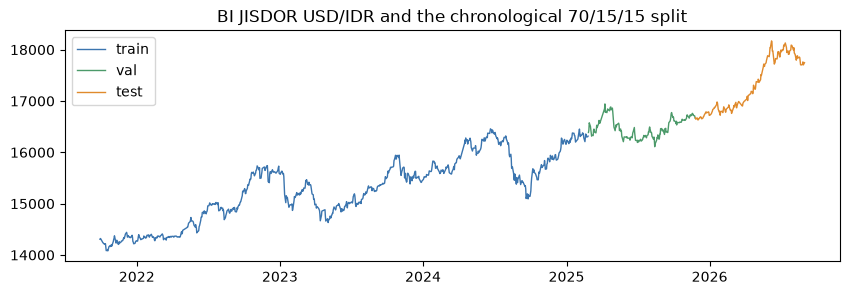

market        9  e.g. ['ret_lag0', 'ret_lag1', 'ret_lag2', 'ret_lag3']
lexicon      19  e.g. ['log_military_conflict', 'log_sanctions', 'log_diplomacy', 'log_trade_conflict']
basic_text   13  e.g. ['vader_mean', 'vader_neg_share', 'vader_pos_share', 'lsa_0']
w2v          18  e.g. ['w2v_pc0', 'w2v_pc1', 'w2v_pc2', 'w2v_pc3']
glove        18  e.g. ['glove_pc0', 'glove_pc1', 'glove_pc2', 'glove_pc3']
minilm       18  e.g. ['minilm_pc0', 'minilm_pc1', 'minilm_pc2', 'minilm_pc3']
finbert      22  e.g. ['finbert_pc0', 'finbert_pc1', 'finbert_pc2', 'finbert_pc3']
minilm_ctx   18  e.g. ['minilm_ctx_pc0', 'minilm_ctx_pc1', 'minilm_ctx_pc2', 'minilm_ctx_pc3']
topics       24  e.g. ['lda_0', 'lda_1', 'lda_2', 'lda_3']
entity       24  e.g. ['ent_central_bank_share', 'ent_central_bank_shock', 'ent_us_share', 'ent_us_shock']


In [3]:
d = df.dropna(subset=["target_ret_next"])
display(d.groupby("split").agg(start=("date","min"), end=("date","max"), days=("date","size"),
        UP_share=("target_up_next","mean"), highvol_share=("target_highvol_next","mean")).loc[["train","val","test"]])
fig, ax = plt.subplots(figsize=(10, 3))
for s, c in (("train", "#3b75af"), ("val", "#4c9a6a"), ("test", "#e08a2c")):
    x = d[d.split == s]; ax.plot(x.date, x.usd_idr, color=c, label=s, lw=1)
ax.set_title("BI JISDOR USD/IDR and the chronological 70/15/15 split"); ax.legend(); plt.show()
for g, cols in G.items(): print(f"{g:11s} {len(cols):3d}  e.g. {cols[:4]}")

**Topic labels** (fit on training headlines only): LDA topics and BERTopic-style MiniLM clusters, each named by its top terms.

In [4]:
display(pd.DataFrame({k: " ".join(v[:7]) for k, v in meta["lda_terms"].items()}, index=["LDA top terms"]).T)
display(pd.DataFrame({k: " ".join(v[:7]) for k, v in meta["cluster_terms"].items()}, index=["cluster c-TF-IDF terms"]).T)

,LDA top terms
lda_0,rights biden saudi mayor orders covid american
lda_1,canada musk congo elon victims families analysis
lda_2,school general states biden united seeks xi
lda_3,court trump supreme judge biden ban election
lda_4,man shooting murder police west prison bank
lda_5,south north korea china military new japan
lda_6,israel gaza killed hamas israeli strike says
lda_7,east pm middle assault foreign new modi
lda_8,house trump congress white bjp elections case
lda_9,china iran says chinese taiwan talks air


,cluster c-TF-IDF terms
clu_0,gaza israel israeli hamas palestinian palestinians hezbollah
clu_1,police man shooting murder arrested trial prison
clu_2,sudan congo niger africa president ethiopia haiti
clu_3,trump biden house election gop republicans democrats
clu_4,iran taliban syria afghanistan pakistan attack says
clu_5,china taiwan chinese chinas says hong military
clu_6,eu nato france poland germany europe says
clu_7,court supreme judge trump lawsuit abortion case
clu_8,bjp india congress pm cm karnataka delhi
clu_9,ukraine russia russian war putin says ukrainian


## 3. Ablation study
### 3a. Live re-computation of the main ablation rows (LogReg, early fusion)
Each block is tuned on validation (C grid × decay half-life h ∈ {0,1,3,5}), refit on train+val and scored once on test.

In [5]:
tr, va, te = splits(df)
mk, B = G["market"], G["lexicon"] + G["basic_text"]
live = []
for bid, cols in [("A", []), ("B", B)] + [(f"C-{r}", G[r]) for r in ("w2v","glove","minilm","minilm_ctx","finbert","topics","entity")]:
    out = run_block(df, mk, cols, "LogReg")
    m = classification_metrics(te.target_up_next, (out["test_proba"] >= .5).astype(int), out["test_proba"])
    live.append({"block": bid, "h": out["halflife"], "C": out["params"]["C"], "val_F1": out["val_score"], **m})
display(pd.DataFrame(live).round(3))

,block,h,C,val_F1,Accuracy,MacroF1,MCC,AUC,p_binom(acc>0.5),n
0,A,0,0.03,0.490,0.579,0.454,0.053,0.542,0.021,178
1,B,1,1.00,0.525,0.478,0.477,-0.026,0.487,0.750,178
2,C-w2v,5,0.01,0.560,0.455,0.383,0.080,0.591,0.899,178
3,C-glove,5,0.03,0.525,0.545,0.544,0.104,0.553,0.130,178
4,C-minilm,0,0.03,0.520,0.562,0.517,0.060,0.534,0.058,178
5,C-minilm_ctx,3,1.00,0.536,0.528,0.514,0.156,0.579,0.250,178
6,C-finbert,1,0.10,0.485,0.545,0.484,0.008,0.503,0.130,178
7,C-topics,0,0.01,0.562,0.489,0.477,-0.047,0.502,0.646,178
8,C-entity,0,0.01,0.534,0.567,0.514,0.065,0.547,0.042,178


### 3b. Full ablation matrix (all models, fusion strategies) — from `results/ablation_all.csv`

=== direction / val ===


,model_id,family,fusion,halflife,Accuracy,MacroF1,MCC,AUC,p_binom(acc>0.5)
0,Majority,naive,-,0,0.520,0.342,0.000,NaN,0.326
1,Persistence,naive,-,0,0.514,0.513,0.027,NaN,0.382
4,A|LogReg,A,-,0,0.565,0.490,0.148,0.501,0.049
6,B|LogReg,B,early,1,0.525,0.525,0.054,0.533,0.274
8,C-w2v|LogReg,C,early,5,0.576,0.560,0.148,0.530,0.025
10,C-glove|LogReg,C,early,5,0.531,0.525,0.056,0.513,0.226
12,C-minilm|LogReg,C,early,0,0.542,0.520,0.075,0.519,0.146
14,C-minilm_ctx|LogReg,C,early,3,0.537,0.536,0.071,0.504,0.184
16,C-finbert|LogReg,C,early,1,0.520,0.485,0.023,0.452,0.326
18,C-topics|LogReg,C,early,0,0.576,0.562,0.148,0.534,0.025


=== direction / test ===


,model_id,family,fusion,halflife,Accuracy,MacroF1,MCC,AUC,p_binom(acc>0.5)
2,Majority,naive,-,0,0.579,0.367,0.000,NaN,0.021
3,Persistence,naive,-,0,0.545,0.533,0.065,NaN,0.130
5,A|LogReg,A,-,0,0.579,0.454,0.053,0.542,0.021
7,B|LogReg,B,early,1,0.478,0.477,-0.026,0.487,0.750
9,C-w2v|LogReg,C,early,5,0.455,0.383,0.080,0.591,0.899
11,C-glove|LogReg,C,early,5,0.545,0.544,0.104,0.553,0.130
13,C-minilm|LogReg,C,early,0,0.562,0.517,0.060,0.534,0.058
15,C-minilm_ctx|LogReg,C,early,3,0.528,0.514,0.156,0.579,0.250
17,C-finbert|LogReg,C,early,1,0.545,0.484,0.008,0.503,0.130
19,C-topics|LogReg,C,early,0,0.489,0.477,-0.047,0.502,0.646


=== volatility / test ===


,model_id,family,fusion,halflife,Accuracy,MacroF1,MCC,AUC,p_binom(acc>0.5)
53,A|LogReg,A,-,0,0.522,0.493,0.033,0.586,0.300
55,B|LogReg,B,early,0,0.539,0.461,0.079,0.539,0.165
57,C-glove|LogReg,C,early,0,0.551,0.515,0.098,0.601,0.101
59,C-entity|LogReg,C,early,5,0.517,0.341,0.000,0.468,0.354
61,C-full|LogReg,C,early,5,0.517,0.361,0.005,0.527,0.354
63,A|LGBM,A,-,0,0.528,0.523,0.051,0.562,0.250
65,B|LGBM,B,early,0,0.567,0.525,0.140,0.621,0.042
67,C-glove|LGBM,C,early,0,0.506,0.491,0.001,0.549,0.470
69,C-entity|LGBM,C,early,0,0.607,0.603,0.211,0.612,0.003
71,C-full|LGBM,C,early,0,0.584,0.549,0.178,0.615,0.015


=== regression (next-day log return, bp) ===


,split,model,family,RMSE_bp,MAE_bp,DirAcc
0,val,RandomWalk (0),naive,33.757,24.615,NaN
1,test,RandomWalk (0),naive,29.187,22.164,NaN
2,val,"ARIMA(0, 0, 2)",A,33.725,24.978,0.503
3,test,"ARIMA(0, 0, 2)",A,28.948,21.967,0.551
4,val,"ARIMAX(0, 0, 2) lexicon shocks",B,33.721,25.114,0.497
5,test,"ARIMAX(0, 0, 2) lexicon shocks",B,29.157,22.275,0.522
6,val,"ARIMAX(0, 0, 2) glove anchors+novelty",C,34.370,25.551,0.542
7,test,"ARIMAX(0, 0, 2) glove anchors+novelty",C,29.303,22.121,0.517


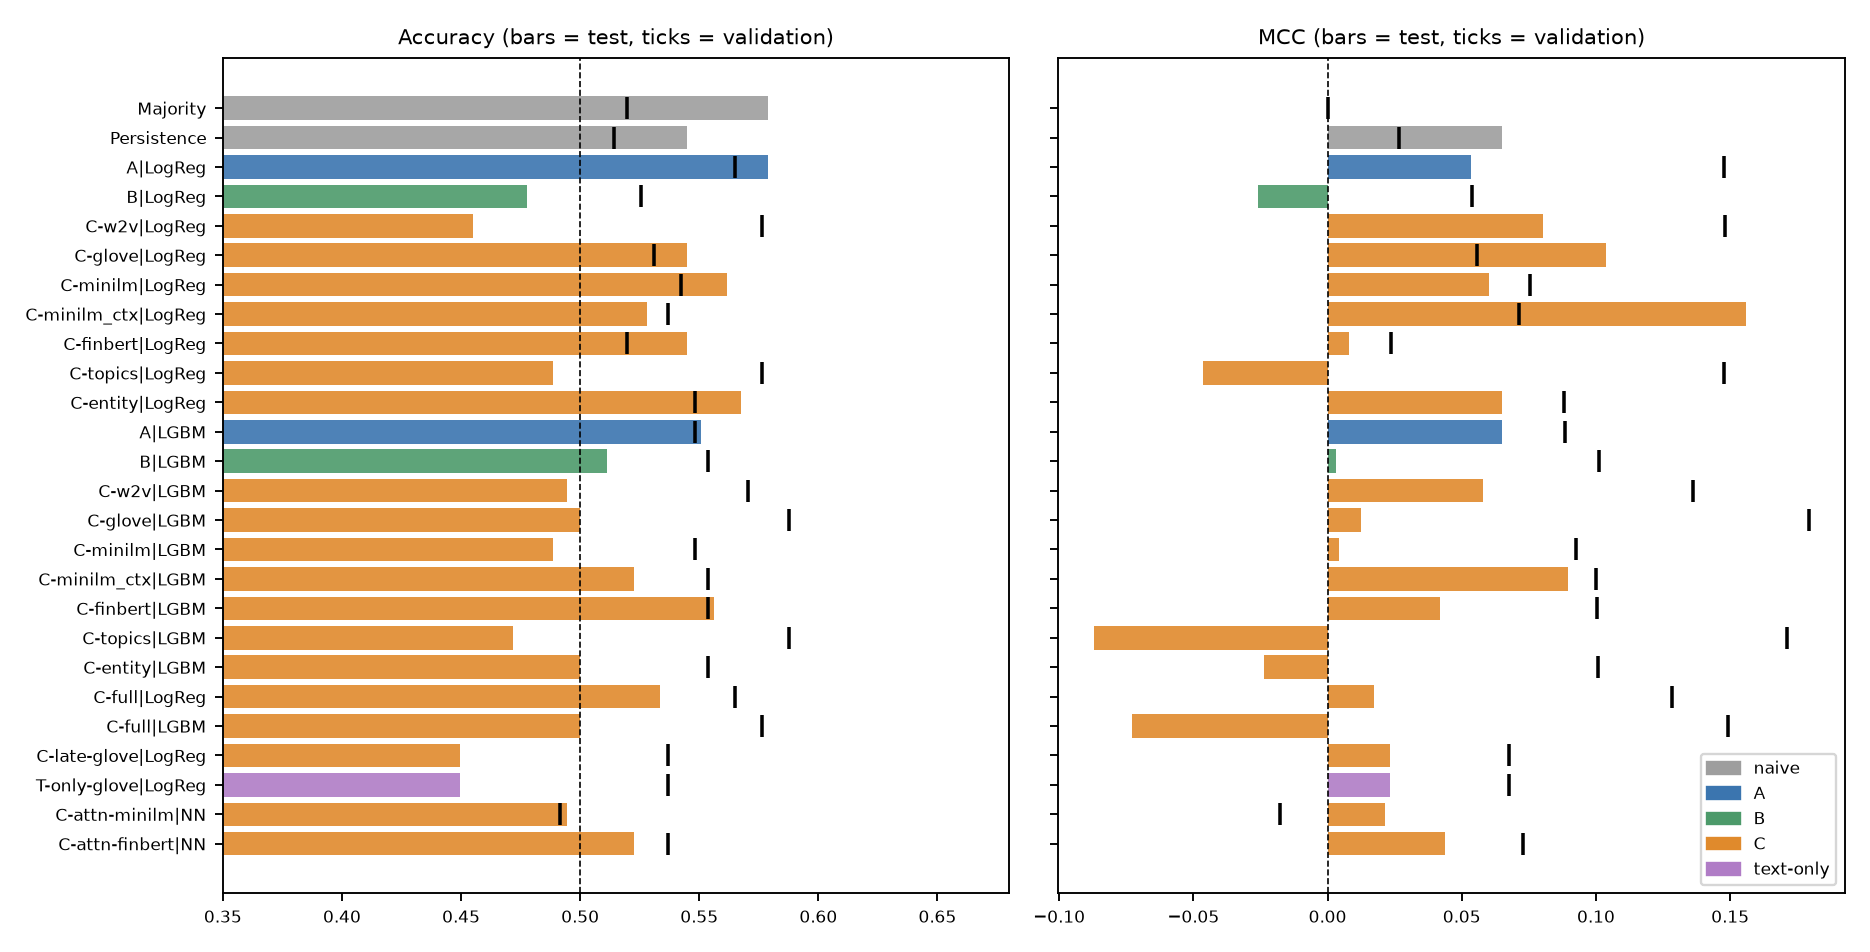

In [6]:
res = pd.read_csv(config.RESULTS / "ablation_all.csv")
cols = ["model_id", "family", "fusion", "halflife", "Accuracy", "MacroF1", "MCC", "AUC", "p_binom(acc>0.5)"]
for tr_, sp in (("direction", "val"), ("direction", "test"), ("volatility", "test")):
    print(f"=== {tr_} / {sp} ==="); display(res[(res.track == tr_) & (res.split == sp)][cols].round(3))
print("=== regression (next-day log return, bp) ===")
display(pd.read_csv(config.RESULTS / "regression_metrics.csv").round(3))
display(Image(str(config.FIGURES / "ablation.png")))

## 4. Robustness: significance tests and rolling-origin evaluation

In [7]:
summ = json.load(open(config.RESULTS / "run_summary.json"))
print("best representation (validation):", summ["best_representation_by_val"])
print("best A / B / C (validation):", summ["best_A"], "/", summ["best_B"], "/", summ["best_C"])
display(pd.DataFrame(summ["mcnemar_test"]).T)
roll = pd.read_csv(config.RESULTS / "rolling_origin.csv")
display(roll.pivot(index="model_id", columns="fold", values="Accuracy").round(3)
        .assign(mean=lambda x: x.mean(1), std=lambda x: x.std(1)).round(3))

best representation (validation): glove
best A / B / C (validation): A|LGBM / B|LGBM / C-glove|LGBM


,p_mcnemar,only_first_right,only_second_right
A|LGBM vs C-glove|LGBM,0.280610,32.0,23.0
B|LGBM vs C-glove|LGBM,0.907561,38.0,36.0
A|LGBM vs B|LGBM,0.463818,37.0,30.0


fold,1,2,3,4,5,6,mean,std
model_id,,,,,,,,
A|LGBM,0.542,0.593,0.441,0.542,0.559,0.417,0.516,0.064
A|LogReg,0.610,0.542,0.475,0.627,0.678,0.417,0.558,0.090
B|LGBM,0.576,0.508,0.492,0.525,0.508,0.517,0.521,0.027
B|LogReg,0.576,0.508,0.525,0.525,0.610,0.400,0.524,0.065
C-glove|LGBM,0.593,0.559,0.475,0.492,0.525,0.500,0.524,0.041
C-glove|LogReg,0.576,0.542,0.492,0.542,0.644,0.433,0.538,0.066


## 5. Embedding space: high- vs low-volatility days

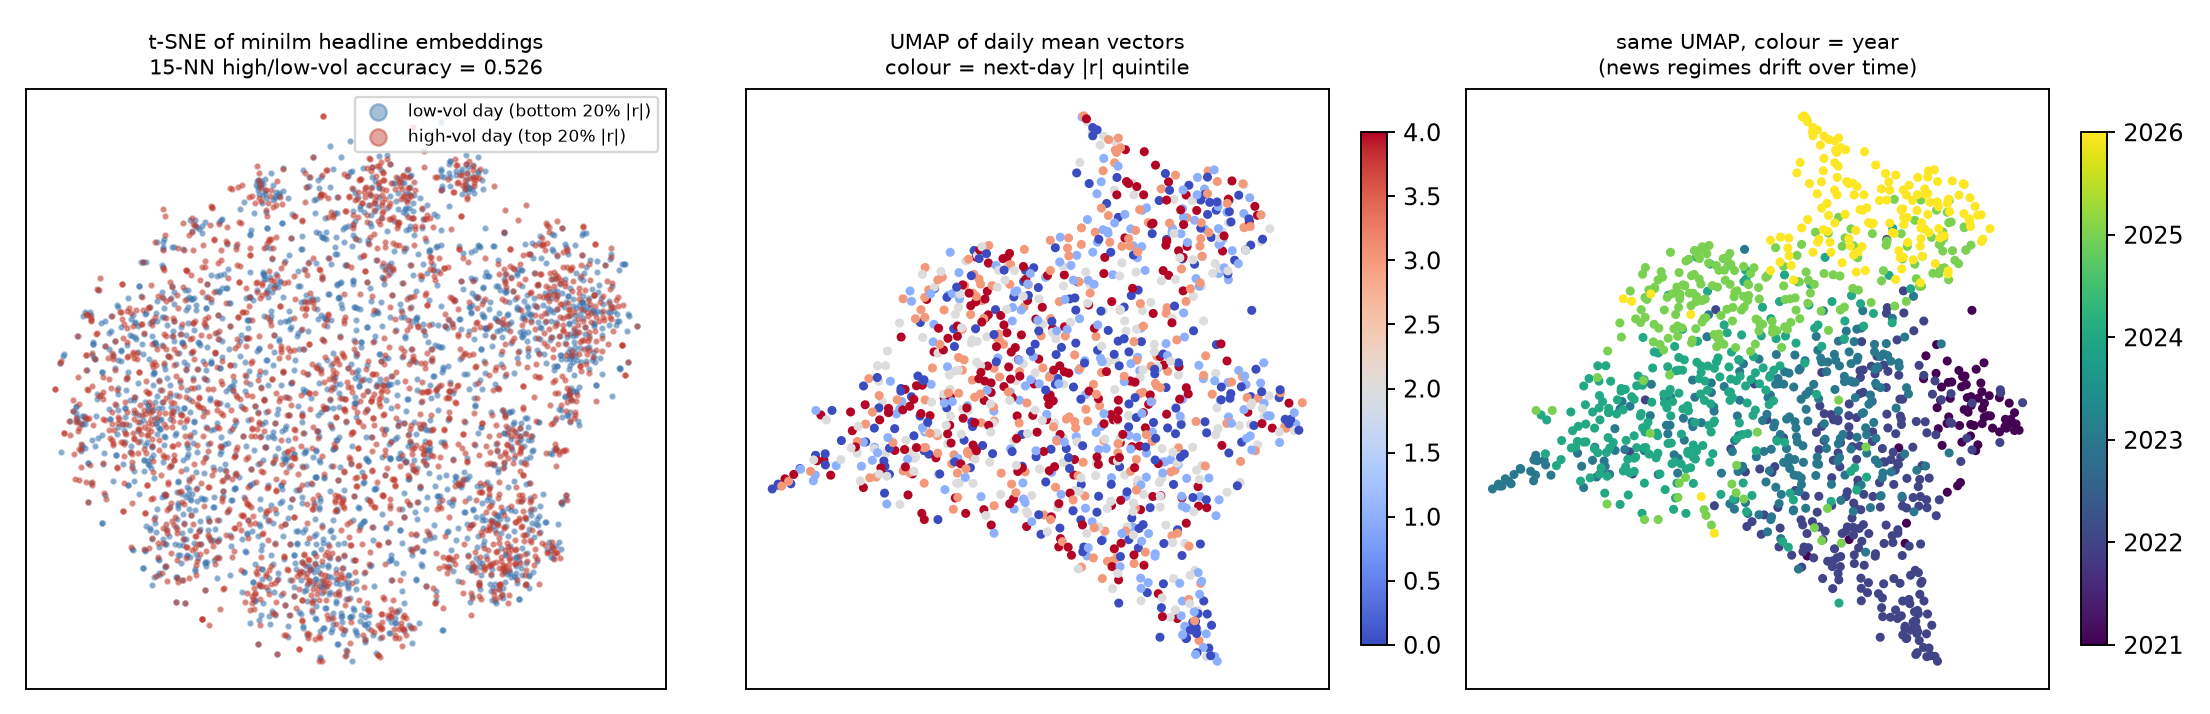

{'knn15_highlow_acc': 0.526, 'rep': 'minilm', 'map': 'UMAP'}


In [8]:
display(Image(str(config.FIGURES / "embedding_space.png")))
print(json.load(open(config.RESULTS / "analysis_summary.json"))["embedding_space"])

## 6. Feature importance & interpretability

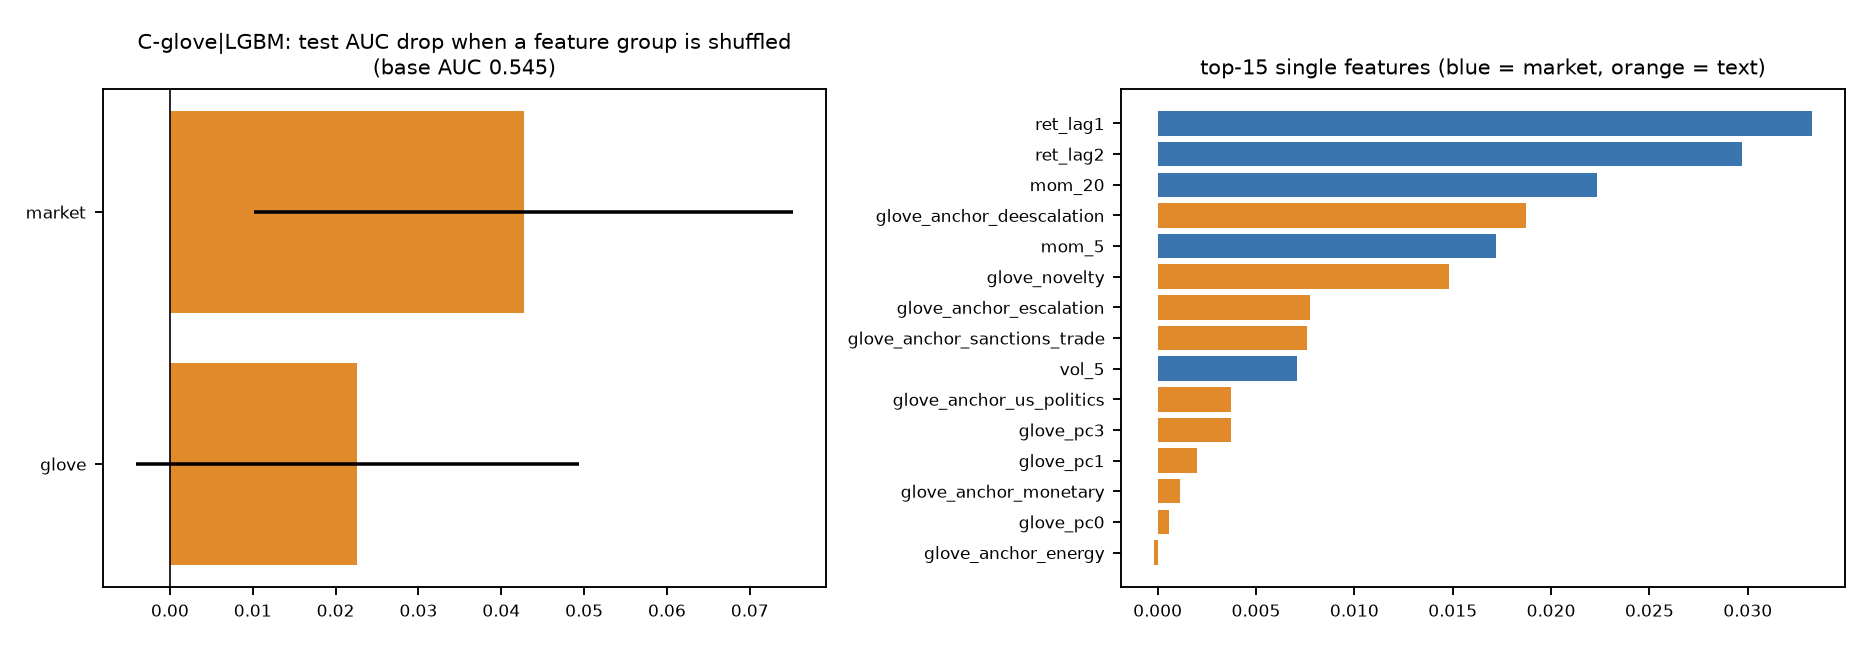

,group,n_features,auc_drop_mean,auc_drop_std
0,market,9,0.0427,0.0325
1,glove,18,0.0226,0.0268


,feature,group,auc_drop
0,ret_lag1,market,0.0332
1,ret_lag2,market,0.0297
2,mom_20,market,0.0223
3,glove_anchor_deescalation,glove,0.0187
4,mom_5,market,0.0172
5,glove_novelty,glove,0.0148
6,glove_anchor_escalation,glove,0.0077
7,glove_anchor_sanctions_trade,glove,0.0076
8,vol_5,market,0.0071
9,glove_anchor_us_politics,glove,0.0037


Topic / anchor / sentiment features most associated with next-day |move| (train+val, Spearman):


,feature,rho_ret,p_ret,rho_absret,p_absret,terms
0,clu_0,0.0265,0.4027,0.0943,0.0028,gaza israel israeli hamas palestinian palestinians
1,ent_middle_east_shock,0.0573,0.0698,-0.0822,0.0092,NaN
2,finbert_anchor_em_stress,0.0081,0.7983,-0.0773,0.0143,NaN
3,finbert_anchor_sanctions_trade,0.0170,0.5906,-0.0732,0.0204,NaN
4,ent_russia_ukraine_shock,0.0171,0.5888,-0.0695,0.0278,NaN
5,lda_8,0.0134,0.6711,-0.0647,0.0404,house trump congress white bjp elections
6,finbert_anchor_energy,0.0372,0.2387,-0.0645,0.0413,NaN
7,lda_6,0.0633,0.0451,0.0641,0.0424,israel gaza killed hamas israeli strike
8,finbert_anchor_china_taiwan,0.0312,0.3231,0.0633,0.0451,NaN
9,ent_us_shock,0.0176,0.5785,-0.0565,0.0734,NaN


In [9]:
display(Image(str(config.FIGURES / "importance.png")))
display(pd.read_csv(config.RESULTS / "importance_groups.csv").round(4))
display(pd.read_csv(config.RESULTS / "importance_features.csv").head(15).round(4))
print("Topic / anchor / sentiment features most associated with next-day |move| (train+val, Spearman):")
display(pd.read_csv(config.RESULTS / "topic_feature_correlations.csv").head(12).round(4))

### Attention over the headline stream
The attention-fusion network learns a weight per headline; these are the headlines it attended to most on test days.

In [10]:
att = pd.read_csv(config.RESULTS / "attention_top_headlines.csv")
display(att[att["rank"] == 1].sort_values("attention", ascending=False).head(15))

,date,rank,attention,headline
264,2026-04-15,1,0.084979,a us navy aircraft carrier is circling africa to reach the middle east
240,2026-04-02,1,0.067805,indian navy was minutes away from striking pakistan from sea during operation sindoor
132,2026-02-02,1,0.066262,isil claims deadly attack on air base near niger
330,2026-05-20,1,0.065188,uae says drones targeted barakah
492,2026-08-10,1,0.062095,who is bhawana kanth how a former tcs engineer became indias first woman top gun combat pilot
51,2025-12-19,1,0.062054,drone strike plunges sudan major
327,2026-05-19,1,0.060429,us military carries out more strikes against isil fighters in nigeria
261,2026-04-14,1,0.058036,nigerian airstrike at village market is latest in which civilians have been killed
354,2026-06-04,1,0.057775,iran war kuwait airport drone strike
210,2026-03-12,1,0.057585,saudi military downs drones targeting shaybah oil field in eastern region


## 7. Error analysis: where did text help, where did it add noise?

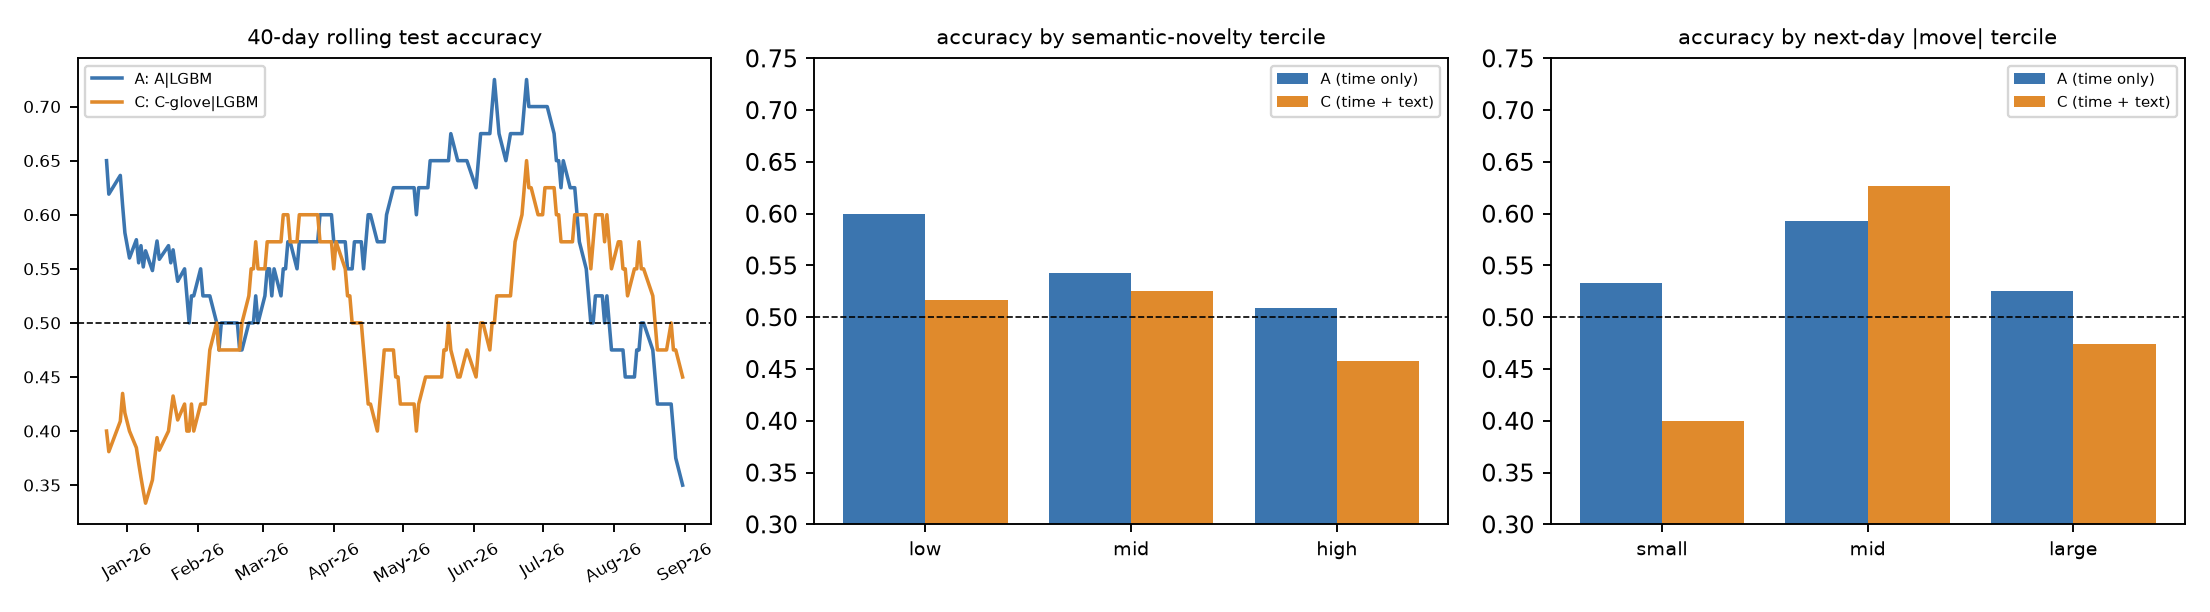

case
both right     66
both wrong     57
text hurt      32
text helped    23
Name: count, dtype: int64

,case,date,y,p_A,p_C,abs_ret_bp,headlines
0,text helped,2026-02-06,DOWN,0.807,0.407,29.1,hong kong ex media tycoon | wa livestock carrier s accused drug collector claims he was trying to save friend | supr...
1,text helped,2026-08-10,UP,0.341,0.728,16.3,todd blanche narrowly confirmed as trumps attorney general in overnight vote | judge blocks hud move change | costa ...
2,text helped,2026-03-16,DOWN,0.674,0.327,4.7,israeli attacks kill in gaza including children and a pregnant woman | ethan hawke will lose at the oscars but he wi...
3,text helped,2026-07-14,DOWN,0.719,0.373,19.4,australia s relationship with india grows ever closer despite one key divergence | europeans sanction russia over al...
4,text helped,2026-02-20,DOWN,0.642,0.310,39.8,i m grieving my old body how a young woman lost her ovary to a surgeon now under investigation | iran covertly repos...
5,text hurt,2026-02-18,UP,0.777,0.365,24.3,cuban drivers face monthslong wait | israeli airstrikes kill in gaza including tent camp palestinian officials say |...
6,text hurt,2026-03-06,UP,0.602,0.242,32.5,azerbaijans foreign ministry accuses iran | russia accuses us and israel of trying to drag arab countries into a wid...
7,text hurt,2026-05-22,UP,0.772,0.499,14.7,first gaza flotilla activists arrive in turkey after israel deportation | gunmen open fire in two separate attacks i...
8,text hurt,2026-07-10,UP,0.577,0.340,34.3,allahabad high court pil police khamenei portraits | indias private credit turning mainstream experts project massiv...
9,text hurt,2025-12-12,UP,0.628,0.417,10.2,how a manosphere star accused of rape and trafficking was freed | sc refuses plea of prajwal revanna for transfer of...


In [11]:
display(Image(str(config.FIGURES / "error_analysis.png")))
ea = pd.read_csv(config.RESULTS / "error_analysis_days.csv")
display(ea.case.value_counts())
display(pd.read_csv(config.RESULTS / "error_examples.csv"))

## 8. Take-aways
See `reports/Task3_Report.pdf` §4–5 for the discussion. In short: the conclusions are drawn from
validation-selected models scored once on test, cross-checked by rolling-origin folds and McNemar tests,
because ~178 test days give a ±7-point noise band on accuracy.